# Notebook 12 – Business Insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.DataFrame({
    "CustomerID": [1001, 1002, 1003, 1004, 1005],
    "Age": [25, 32, 45, 22, 38],
    "MonthlyIncome": [20000, 35000, 50000, 18000, 42000],
    "CustomerType": [
        "New", "Returning", "Returning", "New", "Returning"
    ],
    "Purchased": ["No", "Yes", "Yes", "No", "Yes"],
    "HousePrice_Lakhs": [20, 25, 30, 22, 35]
})

display(df)

,CustomerID,Age,MonthlyIncome,CustomerType,Purchased,HousePrice_Lakhs
0,1001,25,20000,New,No,20
1,1002,32,35000,Returning,Yes,25
2,1003,45,50000,Returning,Yes,30
3,1004,22,18000,New,No,22
4,1005,38,42000,Returning,Yes,35


### Identify important patterns

Pattern 1: Purchase behavior differs by customer type

Visualization: Purchase status by customer type

In [2]:
purchase_table = pd.crosstab(
    df["CustomerType"],
    df["Purchased"]
)

display(purchase_table)

purchase_rate = (
    df.assign(PurchasedFlag=df["Purchased"].eq("Yes"))
      .groupby("CustomerType")["PurchasedFlag"]
      .mean()
      .mul(100)
)

print("Purchase rate by customer type (%):")
display(purchase_rate)

Purchased,No,Yes
CustomerType,,
New,2,0
Returning,0,3


Purchase rate by customer type (%):


CustomerType
New            0.0
Returning    100.0
Name: PurchasedFlag, dtype: float64

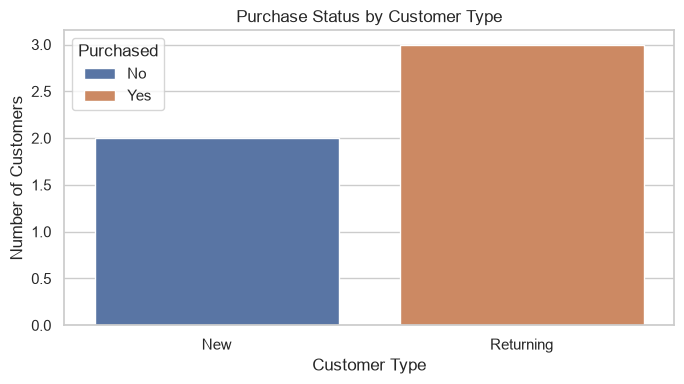

In [3]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="CustomerType",
    hue="Purchased",
    order=["New", "Returning"]
)

plt.title("Purchase Status by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Visualization → Observation → Insight → Action

- Observation: Both New customers did not purchase, while all three Returning customers purchased
- Business insight: The sample suggests that repeat customers may be more likely to purchase than new customers
- Potential business problem: New customers may face barriers during onboarding, product discovery, or the purchase process
- Potential opportunity: Test better onboarding, product demonstrations, or first-purchase offers for new customers
- Validation needed: Analyze a much larger customer sample before concluding that customer type predicts purchasing behavior

Pattern 2: Income differs between purchasers and non-purchasers

In [4]:
income_summary = (
    df.groupby("Purchased")["MonthlyIncome"]
      .agg(["count", "mean", "median", "min", "max"])
)

display(income_summary)

,count,mean,median,min,max
Purchased,,,,,
No,2,19000.000000,19000.0,18000,20000
Yes,3,42333.333333,42000.0,35000,50000


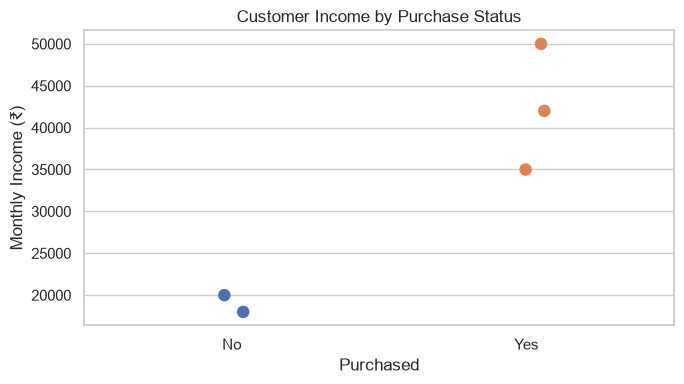

In [5]:
plt.figure(figsize=(7, 4))

sns.stripplot(
    data=df,
    x="Purchased",
    y="MonthlyIncome",
    hue="Purchased",
    jitter=0.08,
    legend=False,
    size=9
)

plt.title("Customer Income by Purchase Status")
plt.xlabel("Purchased")
plt.ylabel("Monthly Income (₹)")
plt.tight_layout()
plt.show()

Observation: Purchasers have monthly incomes of ₹35,000, ₹42,000, and ₹50,000. Non-purchasers have incomes of ₹18,000 and ₹20,000

Business insight: Higher income coincides with purchasing in these five records

Potential business problem: If this pattern holds in a larger dataset, the product or its financing options may be less accessible to lower-income customers

Potential opportunity: Investigate affordable product options, installment plans, or financing eligibility

Validation needed: Check other factors, such as customer needs, preferences, product suitability, and acquisition channel. The observed pattern does not establish that income causes purchasing

Pattern 3: Returning customers are associated with higher house prices

In [6]:
house_price_summary = (
    df.groupby("CustomerType")["HousePrice_Lakhs"]
      .agg(["count", "mean", "median"])
)

display(house_price_summary)

,count,mean,median
CustomerType,,,
New,2,21.0,21.0
Returning,3,30.0,30.0


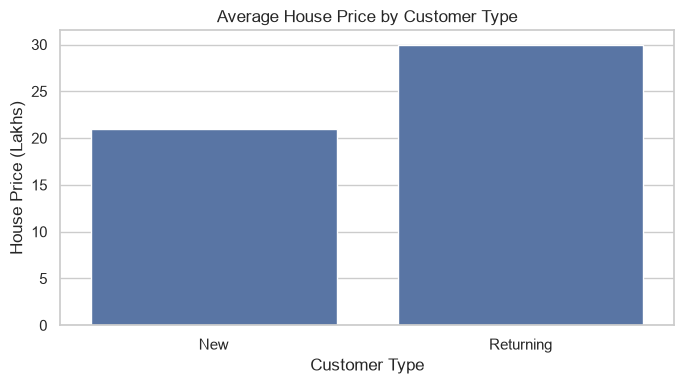

In [7]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=df,
    x="CustomerType",
    y="HousePrice_Lakhs",
    errorbar=None,
    order=["New", "Returning"]
)

plt.title("Average House Price by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("House Price (Lakhs)")
plt.tight_layout()
plt.show()

Observation: New customers have an average house price of ₹21 lakhs; Returning customers have an average of ₹30 lakhs

Business insight: Returning customers are associated with higher-priced properties in this sample

Potential opportunity: Explore whether repeat customers respond well to premium listings or personalized recommendations

Business caution: The house-price column does not establish whether these customers actually purchased the properties at those prices. Confirm what the column represents before using it to infer revenue or transaction value

### Identify trends and relationships

Relationship 1: Monthly income and house price

In [8]:
correlation = df[
    ["MonthlyIncome", "HousePrice_Lakhs"]
].corr().iloc[0, 1]

print(f"Income–house price correlation: {correlation:.3f}")

Income–house price correlation: 0.842


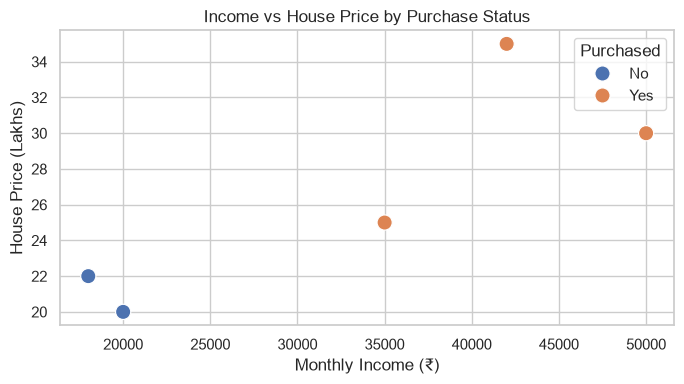

In [9]:
plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=df,
    x="MonthlyIncome",
    y="HousePrice_Lakhs",
    hue="Purchased",
    s=120
)

plt.title("Income vs House Price by Purchase Status")
plt.xlabel("Monthly Income (₹)")
plt.ylabel("House Price (Lakhs)")
plt.tight_layout()
plt.show()

Observation: The five records show a positive association between income and house price

Business insight: Income may help with customer segmentation or affordability analysis

Potential opportunity: Explore income-based recommendations or affordability bands

Limitation: Five records are insufficient to establish a stable correlation or justify a pricing strategy

Relationship 2: Age and purchase behavior

In [10]:
age_summary = (
    df.groupby("Purchased")["Age"]
      .agg(["count", "mean", "median"])
)

display(age_summary)

,count,mean,median
Purchased,,,
No,2,23.500000,23.5
Yes,3,38.333333,38.0


Observation: Purchasers have an average age of approximately 38.3 years, while non-purchasers average 23.5 years

Business insight: Older customers happen to be the purchasers in this sample

Potential opportunity: Investigate whether age groups differ in preferences or purchase needs

Limitation: Do not assume older customers are generally more likely to purchase without checking a larger, representative dataset and relevant confounding factors

### Identify anomalies and data-quality problems

In [11]:

print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(df.isna().sum())

print("\nPurchase categories:")
display(df["Purchased"].value_counts(dropna=False))

display(
    df[["Age", "MonthlyIncome", "HousePrice_Lakhs"]].describe()
)

Duplicate rows: 0

Missing values:


CustomerID          0
Age                 0
MonthlyIncome       0
CustomerType        0
Purchased           0
HousePrice_Lakhs    0
dtype: int64


Purchase categories:


Purchased
Yes    3
No     2
Name: count, dtype: int64

,Age,MonthlyIncome,HousePrice_Lakhs
count,5.000000,5.000000,5.000000
mean,32.400000,33000.000000,26.400000
std,9.396808,13856.406461,6.107373
min,22.000000,18000.000000,20.000000
25%,25.000000,20000.000000,22.000000
50%,32.000000,35000.000000,25.000000
75%,38.000000,42000.000000,30.000000
max,45.000000,50000.000000,35.000000


In [12]:

invalid_age = df[
    (df["Age"] < 18) | (df["Age"] > 100)
]

invalid_income = df[
    df["MonthlyIncome"] < 0
]

invalid_house_price = df[
    df["HousePrice_Lakhs"] <= 0
]

print("Potentially invalid ages:", len(invalid_age))
print("Negative incomes:", len(invalid_income))
print("Non-positive house prices:", len(invalid_house_price))

Potentially invalid ages: 0
Negative incomes: 0
Non-positive house prices: 0


Potential action: Establish data validation rules and investigate flagged records before analysis. Do not remove unusual records automatically.

Other useful checks include:

- Whether CustomerID is unique.
- Whether purchase categories are standardized as Yes and No.
- Whether HousePrice_Lakhs represents a listing price, quoted price, or completed transaction price.
- Whether the dataset includes all eligible customers or only selected customers.

### Identify interesting business segments

In [13]:

df["IncomeSegment"] = pd.cut(
    df["MonthlyIncome"],
    bins=[0, 25000, 40000, float("inf")],
    labels=["Lower", "Middle", "Higher"],
    right=True
)

segment_summary = (
    df.groupby("IncomeSegment", observed=False)
      .agg(
          Customers=("CustomerID", "count"),
          Purchases=(
              "Purchased",
              lambda x: (x == "Yes").sum()
          ),
          AverageHousePrice=("HousePrice_Lakhs", "mean")
      )
      .reset_index()
)

segment_summary["PurchaseRate_pct"] = (
    segment_summary["Purchases"]
    / segment_summary["Customers"].replace(0, np.nan)
    * 100
)

display(segment_summary)

,IncomeSegment,Customers,Purchases,AverageHousePrice,PurchaseRate_pct
0,Lower,2,0,21.0,0.0
1,Middle,1,1,25.0,100.0
2,Higher,2,2,32.5,100.0


These income bands are illustrative, not validated market segments. Set meaningful thresholds based on business context and sufficient data.

Potential insights to investigate:

- Lower-income segment: Are affordability, financing, or product fit barriers preventing purchases?
- Middle-income segment: Which features or offers help customers convert?
- Higher-income segment: Is there demand for premium properties or personalized services?
Do not interpret a segment with very few customers—or no customers—as evidence of a reliable business trend.

In [ ]:

Use the evidence from your EDA to propose testable actions rather than assuming that a pattern guarantees a business result

        Observed pattern	                                      Potential opportunity	                                           How to validate

New customers did not purchase in this sample	   Improve onboarding and first-purchase support	Measure conversion among a larger new-customer cohort
Purchasers have higher incomes in this sample	   Investigate affordability and financing options	Compare conversion by income segment while accounting for other factors
Returning customers are associated with higher     house prices	Test personalized premium listings	Compare engagement and completed purchases across customer types
Age and purchasing differ in this sample	       Explore customer needs by age group           	Analyze a larger sample and control for relevant differences
Dataset has only five records                            Improve data collection	                 Obtain more representative records with clear outcome definitions

These are hypotheses to test, not proven recommendations. If possible, use controlled experiments to evaluate whether an intervention actually improves conversion, revenue, or customer satisfaction.